# Bagur 2025 — mouse inferior colliculus, thalamus and auditory cortex

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/urancon/deepSTRF/blob/develop/examples/inspect_bagur2025.ipynb)

This notebook is a **visual tour** of the deepSTRF loader for the
**[Bagur et al. 2025](https://doi.org/10.1126/sciadv.adr6214)** (*Science
Advances*) mouse dataset: 140 sounds, 13–15 repeats each, played to awake mice
while recording the inferior colliculus (IC), the auditory thalamus (TH) and
the auditory cortex (AC), with two-photon imaging and silicon probes.

We cover:

- loading a population and the stimulus categories;
- single-unit responses to a tone and to a frequency sweep;
- the **cochlear model** as an alternative input to the spectrogram;
- the **positions of the AC neurons** on the cortical surface, with their best
  frequency and subfield;
- the leak-aware `group_split`;
- imaging of thalamic axon boutons, and the calcium lag.

See the [dataset page](../md/README_Bagur_2025.md) for every metadata key and caveat.

## Setup — Google Colab

The cell below installs deepSTRF from source on Colab. On a local install
(`pip install -e .`) it's a no-op.

**Note on data.** `download=True` fetches only what each call needs from
Zenodo: the code and sound archives (250 MB), then 154 MB for IC
electrophysiology, 1.5 GB for the cochlear model, 6.7 GB for AC and 1.5 GB for
TH imaging. AC imaging needs about 8 GB of RAM. If you already have the release
unpacked, point `BAGUR2025_DATA` at that folder.

In [1]:
import sys
if 'google.colab' in sys.modules:
    !pip install -q git+https://github.com/urancon/deepSTRF.git
    print("deepSTRF installed from GitHub.")
else:
    print("Local environment — assuming deepSTRF is already importable.")

Local environment — assuming deepSTRF is already importable.


In [2]:
import os
import warnings
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np

warnings.filterwarnings("ignore", message="IProgress not found")   # tqdm in a notebook without ipywidgets
from deepSTRF.datasets.audio import Bagur2025Dataset
from deepSTRF.utils import plot_stim_with_response

PATH = os.environ.get("BAGUR2025_DATA")             # None -> deepSTRF's cache folder
ds = Bagur2025Dataset(PATH, areas="IC", method="ephys", download=PATH is None)

print(f"{ds.N_neurons} IC single units, {len(ds.stim_meta)} sounds, dt = {ds.dt} ms, "
      f"{ds.stims[0].shape[-1]} bins per trial, {ds.F} spectrogram bands")
print(f"responses[s][n]: {tuple(ds.responses[0][0].shape)} (repeats x time bins), raw spike counts")
for cat, n in sorted(Counter(m["category"] for m in ds.stim_meta).items()):
    print(f"  {cat:16s} {n:3d}")

442 IC single units, 140 sounds, dt = 5.0 ms, 300 bins per trial, 31 spectrogram bands
responses[s][n]: (14, 300) (repeats x time bins), raw spike counts
  am                12
  blank              1
  chirp_durations   12
  chirps            40
  down_ramps        21
  pure_tones        33
  up_ramps          21


## A tone and a frequency sweep

Each trial runs from 500 ms before the sound to 1 s after its onset. We pick
the IC unit with the strongest response to a 70-dB tone at its best frequency,
and show its responses to that tone and to a 500 ms upward sweep.

unit IC-ephys_00331 (IC-L): best frequency 12.258 kHz, spontaneous rate 0.1 spikes/s


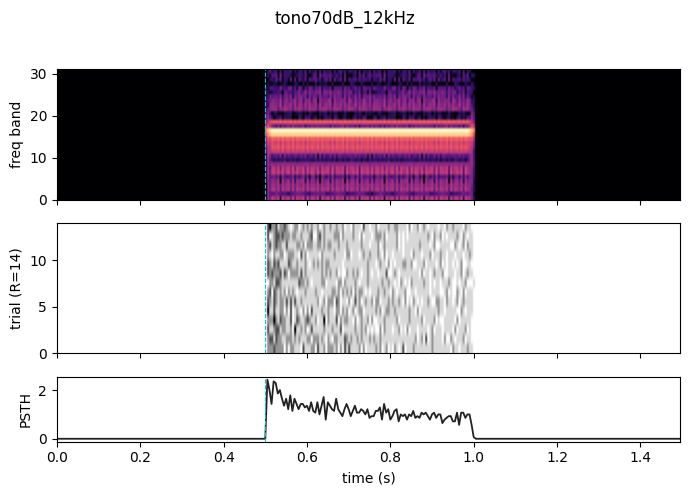

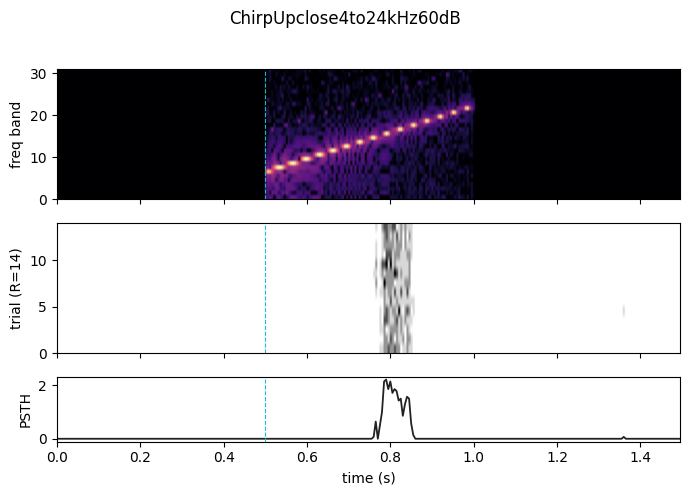

In [3]:
names = [m["name"] for m in ds.stim_meta]
tone70 = {m["frequency_khz"][0]: s for s, m in enumerate(ds.stim_meta) if m["group"] == "pure_70dB"}
evoked = np.full(ds.N_neurons, -np.inf)
for n, meta in enumerate(ds.nrn_meta):
    if meta["best_freq_khz"] is None:                 # no excitatory response to any tone
        continue
    r = ds.responses[tone70[meta["best_freq_khz"]]][n].mean(0).numpy()
    evoked[n] = r[100:200].mean() - r[:100].mean()    # 0-500 ms minus baseline (5 ms bins)
n_best = int(np.argmax(evoked))
meta = ds.nrn_meta[n_best]
print(f"unit {meta['cell_id']} ({meta['subdivision']}): best frequency {meta['best_freq_khz']:g} kHz, "
      f"spontaneous rate {meta['spont_rate']:.1f} spikes/s")

for s in (tone70[meta["best_freq_khz"]], names.index("ChirpUpclose4to24kHz60dB")):
    fig, axes = plot_stim_with_response(ds.stims[s], ds.responses[s][n_best], dt_ms=ds.dt,
                                        title=names[s], figsize=(7, 5))
    for ax in axes:
        ax.axvline(0.5, color="tab:cyan", lw=0.8, ls="--")
    plt.show()

*Top to bottom: the stimulus spectrogram (31 log-spaced bands, 2–64 kHz), the
raster (one row per repeat, darker = more spikes in the 5 ms bin) and the PSTH
(mean spike count per 5 ms bin); time runs from the trial start, the sound
starting at 0.5 s (dashed line). The unit, in the lateral IC, fires a sharp
onset burst then a sustained response for the whole 500 ms tone at its best
frequency (12.26 kHz), and almost never outside it. On the 4→24 kHz upward
sweep it fires for about 70 ms, around 0.28–0.35 s after onset: when the
sweep, logarithmic in frequency, crosses its best frequency (12 kHz is reached
at ~310 ms). This unit was picked as the strongest tone responder, so it is
cleaner than most.*

## The cochlear model as input

`spec_backend="cochlear_model"` swaps the spectrogram for the release's
cochlear model (657 auditory-nerve fibres, mean of 15 noisy repeats), shaped
like a spectrogram so any deepSTRF model can take it. The release gives no
channel metadata: `cochlear_cf_khz` is an approximate characteristic frequency
fitted from the fibres' tone responses.

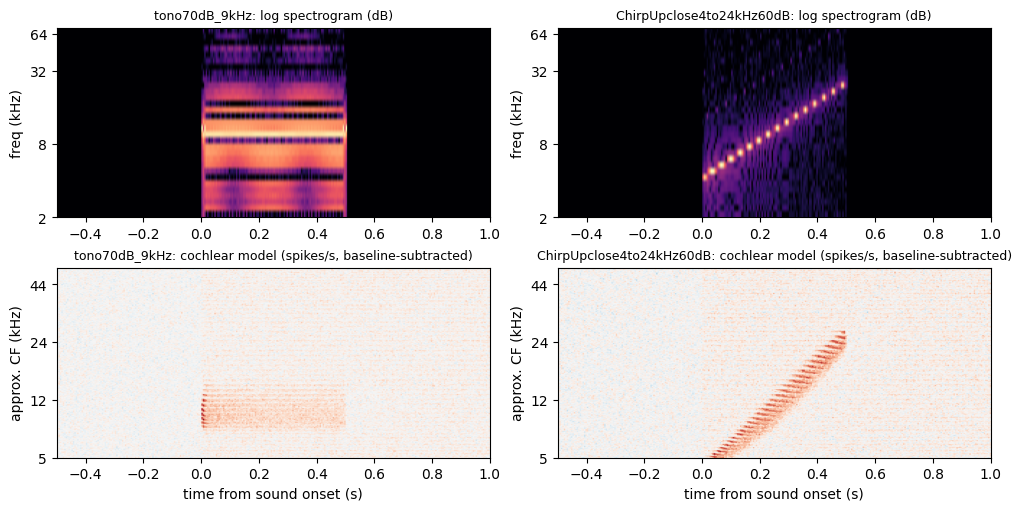

In [4]:
ds_cc = Bagur2025Dataset(PATH, areas="IC", method="ephys", spec_backend="cochlear_model",
                         download=PATH is None)
cf = ds_cc.cochlear_cf_khz
t = np.arange(ds.stims[0].shape[-1]) * ds.dt / 1000 - 0.5
fig, axes = plt.subplots(2, 2, figsize=(10, 5), constrained_layout=True)
for j, s in enumerate((tone70[9.798], names.index("ChirpUpclose4to24kHz60dB"))):
    axes[0, j].imshow(ds.stims[s][0], origin="lower", aspect="auto", cmap="magma",
                      extent=[t[0], t[-1] + ds.dt / 1000, 0, ds.F])
    axes[0, j].set_title(f"{names[s]}: log spectrogram (dB)", fontsize=9)
    axes[0, j].set_yticks([0, 12, 24, 30], ["2", "8", "32", "64"])
    axes[0, j].set_ylabel("freq (kHz)")
    x = ds_cc.stims[s][0].numpy()
    axes[1, j].imshow(x, origin="lower", aspect="auto", cmap="RdBu_r",
                      vmin=-np.abs(x).max(), vmax=np.abs(x).max(),
                      extent=[t[0], t[-1] + ds.dt / 1000, 0, len(cf)])
    axes[1, j].set_title(f"{names[s]}: cochlear model (spikes/s, baseline-subtracted)", fontsize=9)
    ticks = [0, 200, 400, 600]
    axes[1, j].set_yticks(ticks, [f"{cf[i]:.0f}" for i in ticks])
    axes[1, j].set_ylabel("approx. CF (kHz)")
    axes[1, j].set_xlabel("time from sound onset (s)")
plt.show()

*Top: the default log spectrogram of a 9.8 kHz tone and of the 4→24 kHz
sweep. Bottom: the cochlear-model input for the same sounds, 657 fibres
ordered by their approximate characteristic frequency (red = above the
fibre's pre-stimulus rate, blue = below; the release subtracts each trial's
baseline, so the input is signed). The tone drives a band of fibres around
9–12 kHz, strongest at onset (adaptation); the sweep drives a moving band,
entering at the lowest fibres (~5 kHz) shortly after onset since the sweep
starts at 4 kHz. Labels above ~37 kHz are extrapolated (no tone reaches those
fibres).*

## Where the AC neurons are

The AC imaging release gives each neuron's position on the cortical surface
(after aligning the mice on their tonotopic maps) and its subfield. Here they
are coloured by the loader's `best_freq_khz` and by subfield. AC imaging
takes about 8 GB of RAM.

19414 AC neurons; 71 without a best frequency; subfields: {'AI': 13907, 'VPAF': 58, None: 968, 'SRAF': 2257, 'DP': 1088, 'AAF': 1136}


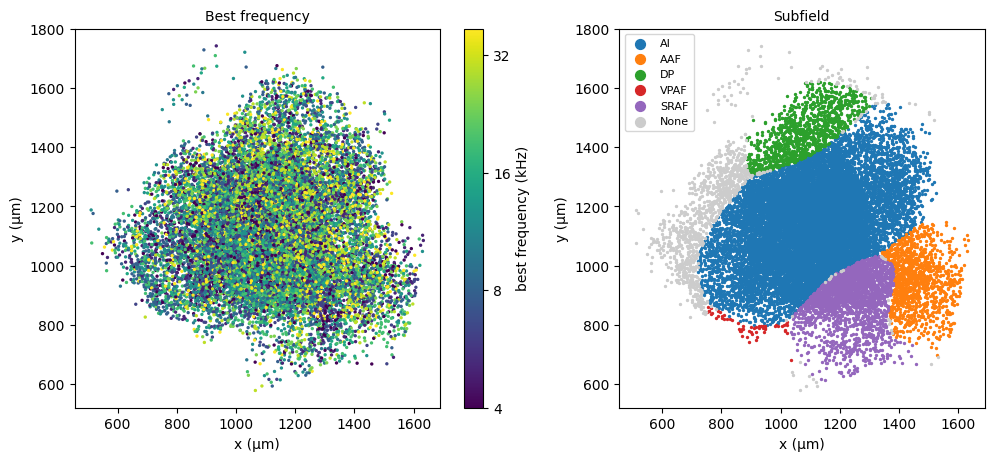

In [5]:
ds_ac = Bagur2025Dataset(PATH, areas="AC", method="2p", download=PATH is None)
x = np.array([m["x_um"] for m in ds_ac.nrn_meta])
y = np.array([m["y_um"] for m in ds_ac.nrn_meta])
bf = np.array([np.nan if m["best_freq_khz"] is None else m["best_freq_khz"] for m in ds_ac.nrn_meta])
sub = [m["subfield"] for m in ds_ac.nrn_meta]
print(f"{ds_ac.N_neurons} AC neurons; {np.isnan(bf).sum()} without a best frequency; "
      f"subfields: {dict(Counter(sub))}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), constrained_layout=True)
ok = ~np.isnan(bf)
sc = axes[0].scatter(x[ok], y[ok], c=np.log2(bf[ok]), s=2, cmap="viridis")
cb = fig.colorbar(sc, ax=axes[0])
ticks = [4, 8, 16, 32]
cb.set_ticks(np.log2(ticks), labels=[str(v) for v in ticks]); cb.set_label("best frequency (kHz)")
axes[0].set_title("Best frequency", fontsize=10)
for name in ["AI", "AAF", "DP", "VPAF", "SRAF", None]:
    m = np.array([s == name for s in sub])
    axes[1].scatter(x[m], y[m], s=2, label=str(name), color="0.8" if name is None else None)
axes[1].legend(markerscale=5, fontsize=8)
axes[1].set_title("Subfield", fontsize=10)
for ax in axes:
    ax.set_xlabel("x (µm)"); ax.set_ylabel("y (µm)"); ax.set_aspect("equal")
plt.show()

*Each dot is one AC neuron at its position on the cortical surface (all
19,414 imaged neurons, all mice, aligned on the tonotopic maps). Left: coloured
by the loader's best frequency (70-dB tone with the largest response over
0–500 ms; 71 neurons have none and are left out). Right: coloured by the
subfield given in the release (AI, AAF, DP, VPAF, SRAF; grey: unassigned). The
subfields tile the surface as expected, AI largest. The best-frequency map is
dominated by neuron-to-neuron scatter (salt-and-pepper); any large-scale
tonotopic gradient is not visible at this single-neuron resolution, and would
need spatial smoothing (as in the authors' DataPresentation code) to show.*

## Train / val / test split

`group_split` keeps together the sounds that are the same waveform up to a
gain (60 / 70 / 80 dB copies, and four sweeps the release ships under two
names) and draws the rest category by category. A seed gives the same split
whichever population is loaded.

In [6]:
split = ds.group_split(seed=0)
cats = sorted(set(m["category"] for m in ds.stim_meta))
print(f"{'category':16s} train  val test")
for c in cats:
    row = [sum(ds.stim_meta[i]["category"] == c for i in split[k]) for k in ("train", "val", "test")]
    print(f"{c:16s} {row[0]:5d} {row[1]:4d} {row[2]:4d}")
print(f"{'total':16s} {len(split['train']):5d} {len(split['val']):4d} {len(split['test']):4d}")

category         train  val test
am                   8    1    3
blank                1    0    0
chirp_durations      9    1    2
chirps              26    4   10
down_ramps          15    2    4
pure_tones          24    3    6
up_ramps            15    2    4
total               98   13   29


## Thalamic boutons and cortical neurons (2-photon)

Imaging has its own time base (~31.7 ms frames). The values are deconvolved
calcium signals: signed, smoothed, and lagging firing by about 100 ms. Here, the
thalamic bouton and the AC neuron with the strongest response to a 70-dB tone
at their best frequency.

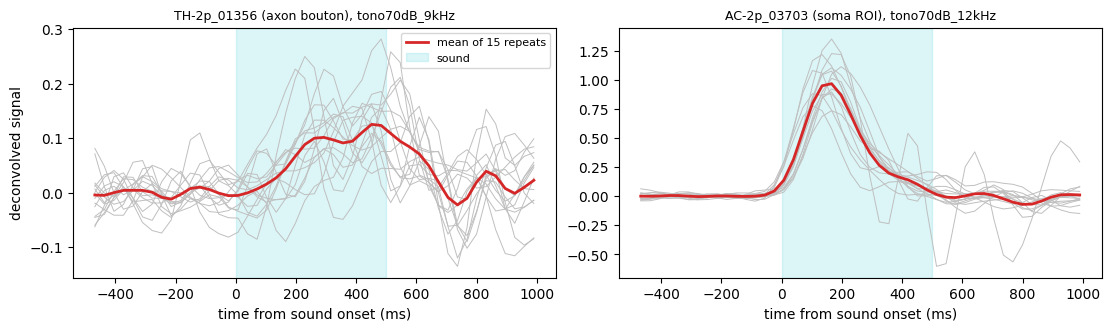

In [7]:
ds_th = Bagur2025Dataset(PATH, areas="TH", method="2p", download=PATH is None)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2), constrained_layout=True, sharey=False)
for ax, d in zip(axes, (ds_th, ds_ac)):
    t70 = {m["frequency_khz"][0]: s for s, m in enumerate(d.stim_meta) if m["group"] == "pure_70dB"}
    best, val = None, -np.inf
    for n, m in enumerate(d.nrn_meta):
        if m["best_freq_khz"] is not None:
            v = d.responses[t70[m["best_freq_khz"]]][n].mean(0)[16:32].mean().item()
            if v > val:
                best, val = (n, t70[m["best_freq_khz"]]), v
    n, s = best
    r = d.responses[s][n].numpy()
    tt = d.twop_frame_times_s * 1000
    ax.plot(tt, r.T, color="0.75", lw=0.7)
    ax.plot(tt, r.mean(0), color="tab:red", lw=2, label=f"mean of {r.shape[0]} repeats")
    ax.axvspan(0, 500, color="tab:cyan", alpha=0.15, label="sound")
    ax.set_title(f"{d.nrn_meta[n]['cell_id']} ({d.nrn_meta[n]['unit_type']}), {d.stim_meta[s]['name']}",
                 fontsize=9)
    ax.set_xlabel("time from sound onset (ms)")
axes[0].set_ylabel("deconvolved signal"); axes[0].legend(fontsize=8)
plt.show()

*The deconvolved 2-photon signal of one TH axon bouton (left) and one AC
neuron (right) to a 70-dB tone at their best frequency: grey, single repeats;
red, their mean; cyan, the sound. Each is the strongest responder of its
population. The AC neuron rises ~50 ms after onset and peaks at ~150 ms, the
calcium lag; it is back to baseline before the sound ends (an onset-dominated
response). The bouton's signal is much smaller (~0.1 vs ~1) and noisier, as
expected for a single axon bouton, with a dip after the sound ends. Imaging
frames are ~31.7 ms; the time axis uses the released frame times.*